In [1]:

import pandas as pd

df = pd.read_csv("../01_Dataset/Sample - Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:

# Check dataset information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18 

In [3]:

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert date columns
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Create new columns for analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%B")

# Check cleaned data
print("Cleaned dataset shape:", df.shape)
print("Invalid order dates:", df["Order Date"].isna().sum())

df.head()


Cleaned dataset shape: (9994, 24)
Invalid order dates: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October


In [4]:

# Save cleaned dataset
df.to_csv(
    "cleaned_superstore.csv",
    index=False
)

print("Cleaned dataset saved successfully!")



Cleaned dataset saved successfully!


In [5]:

# Calculate business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("===== E-COMMERCE SALES ANALYSIS =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Customers: {total_customers}")



===== E-COMMERCE SALES ANALYSIS =====
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5009
Total Customers: 793


Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


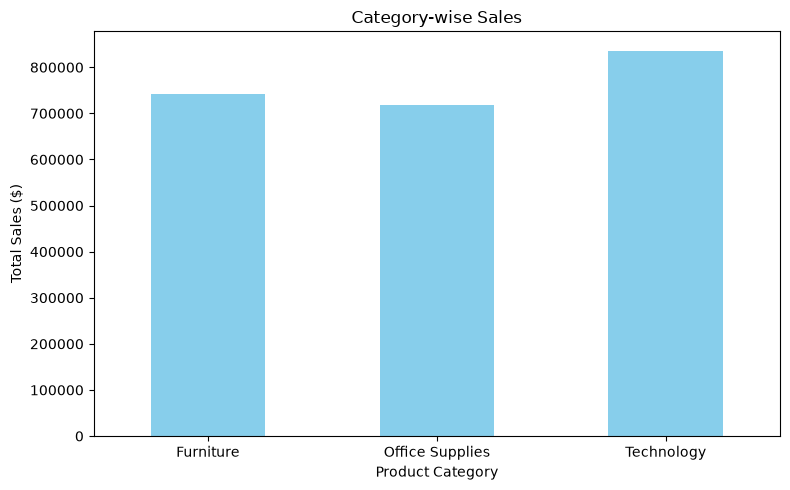

In [6]:

import matplotlib.pyplot as plt

category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

category_sales.plot(
    kind="bar",
    color="skyblue",
    figsize=(8, 5)
)

plt.title("Category-wise Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


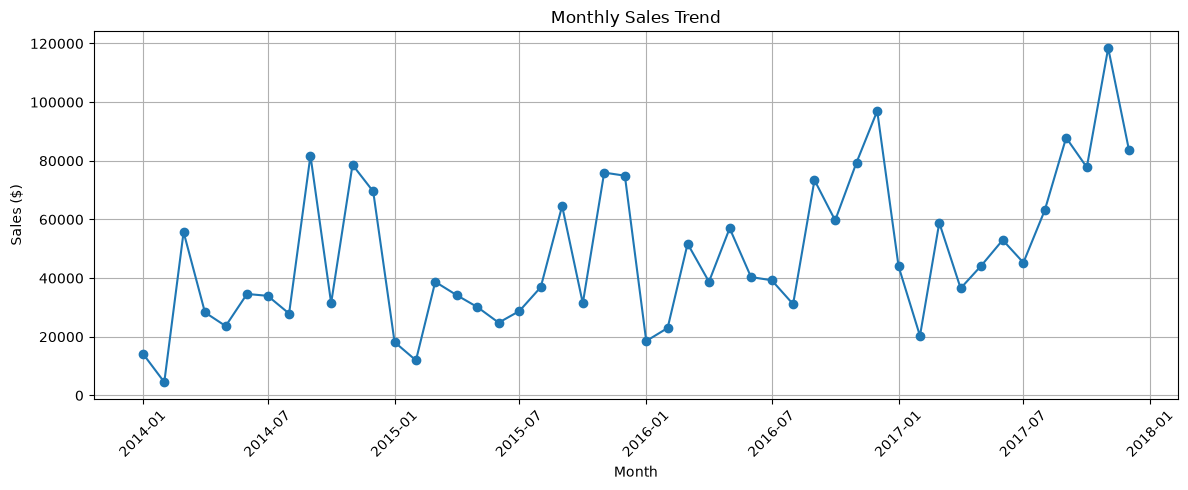

In [7]:

monthly_sales = (
    df.groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

monthly_sales["Date"] = pd.to_datetime(
    monthly_sales[["Year", "Month"]].assign(DAY=1)
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


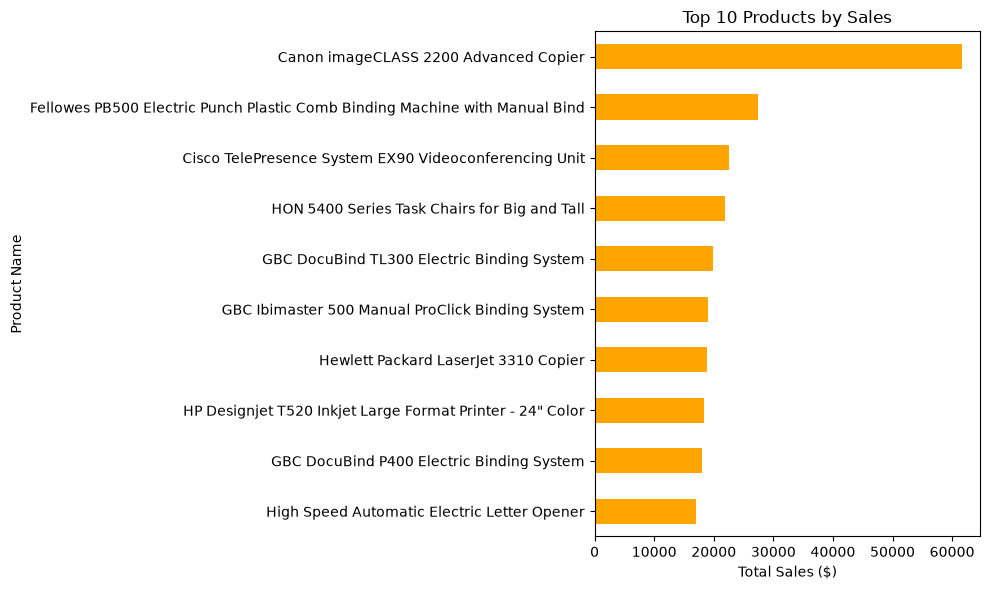

In [8]:

top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .nlargest(10)
)

print(top_products)

top_products.sort_values().plot(
    kind="barh",
    color="orange",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


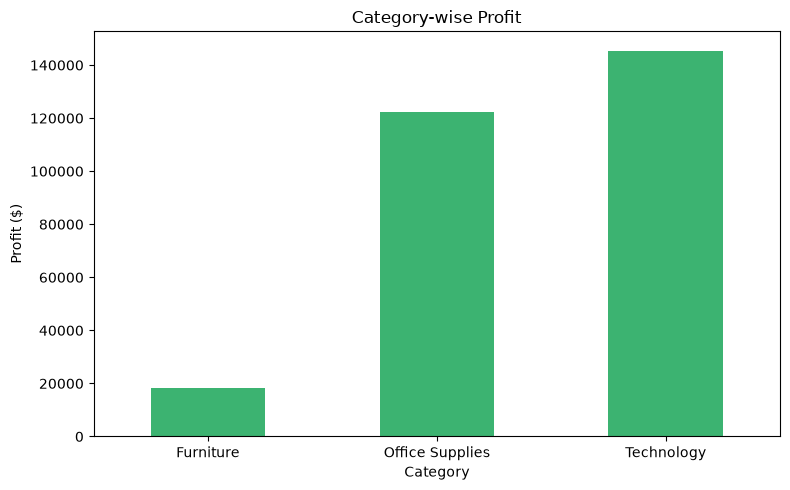

In [9]:

category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

category_profit.plot(
    kind="bar",
    color="mediumseagreen",
    figsize=(8, 5)
)

plt.title("Category-wise Profit")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Customer ID
SM-20320    25043.050
TC-20980    19052.218
RB-19360    15117.339
TA-21385    14595.620
AB-10105    14473.571
KL-16645    14175.229
SC-20095    14142.334
HL-15040    12873.298
SE-20110    12209.438
CC-12370    12129.072
Name: Sales, dtype: float64


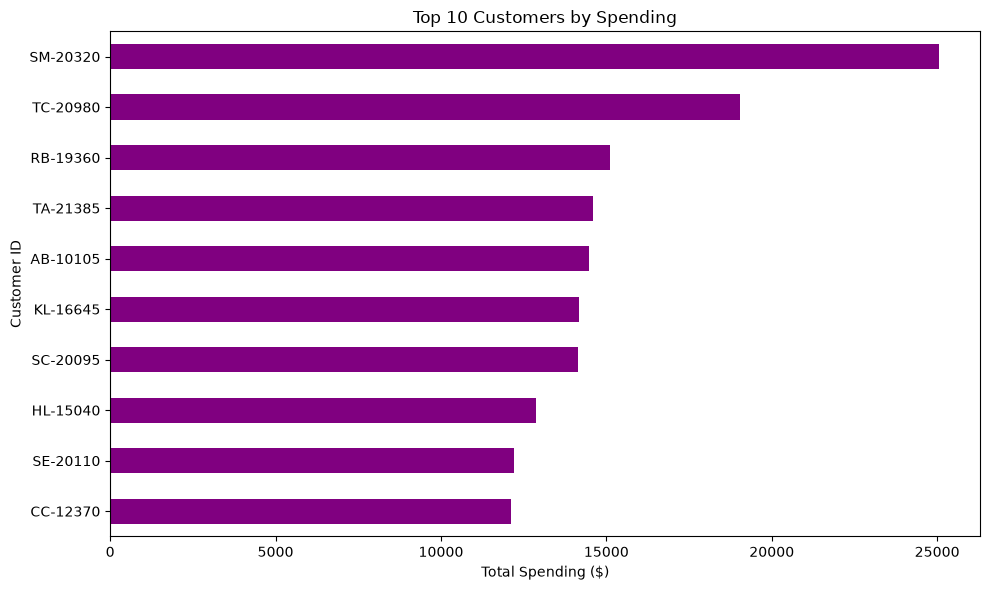

In [10]:

# Top 10 customers by spending

top_customers = (
    df.groupby("Customer ID")["Sales"]
    .sum()
    .nlargest(10)
)

print(top_customers)

top_customers.sort_values().plot(
    kind="barh",
    color="purple",
    figsize=(10, 6)
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending ($)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


Repeat Customers: 781
One-time Customers: 12


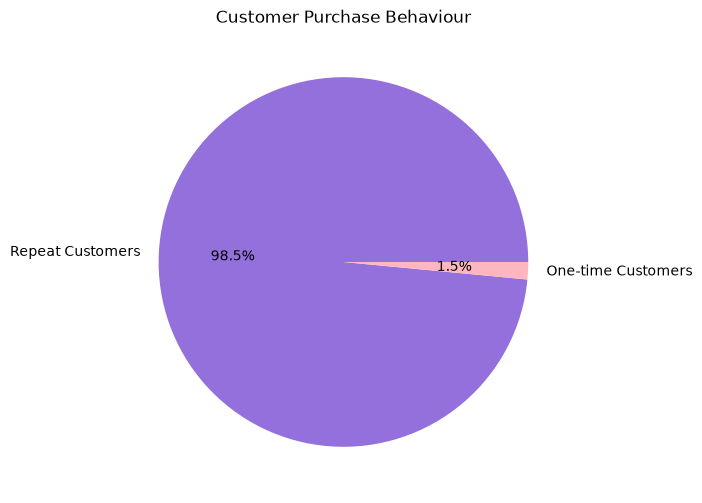

In [11]:

# Count unique orders per customer

customer_orders = df.groupby("Customer ID")["Order ID"].nunique()

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)

plt.figure(figsize=(6, 6))
plt.pie(
    [repeat_customers, one_time_customers],
    labels=["Repeat Customers", "One-time Customers"],
    autopct="%1.1f%%",
    colors=["mediumpurple", "lightpink"]
)

plt.title("Customer Purchase Behaviour")
plt.show()


In [12]:

# Calculate average order value

order_revenue = df.groupby("Order ID")["Sales"].sum()

average_order_value = order_revenue.mean()

print(f"Average Order Value: ${average_order_value:,.2f}")


Average Order Value: $458.61


In [13]:

import sqlite3
import pandas as pd

# Connect to SQLite database
conn = sqlite3.connect("ecommerce_sales.db")

# Prepare data for SQL
sql_df = df.copy()

sql_df["Order Date"] = sql_df["Order Date"].dt.strftime("%Y-%m-%d")
sql_df["Ship Date"] = sql_df["Ship Date"].dt.strftime("%Y-%m-%d")

# Create SQL table
sql_df.to_sql(
    "orders",
    conn,
    if_exists="replace",
    index=False
)

print("SQL Database Created Successfully!")


SQL Database Created Successfully!


In [14]:

query = "SELECT * FROM orders LIMIT 5;"

result = pd.read_sql_query(query, conn)

display(result)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October


In [15]:

query = """
SELECT
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM orders;
"""

display(pd.read_sql_query(query, conn))


,Total_Sales,Total_Profit
0,2297200.86,286397.02


In [16]:

query = """
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales
FROM orders
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

display(pd.read_sql_query(query, conn))


,Category,Total_Sales
0,Technology,836154.03
1,Furniture,741999.80
2,Office Supplies,719047.03


In [17]:

query = """
SELECT
    "Product Name",
    ROUND(SUM(Sales), 2) AS Total_Sales
FROM orders
GROUP BY "Product Name"
ORDER BY Total_Sales DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))


,Product Name,Total_Sales
0,Canon imageCLASS 2200 Advanced Copier,61599.82
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,GBC DocuBind TL300 Electric Binding System,19823.48
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,Hewlett Packard LaserJet 3310 Copier,18839.69
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,GBC DocuBind P400 Electric Binding System,17965.07
9,High Speed Automatic Electric Letter Opener,17030.31


In [18]:

query = """
SELECT
    Year,
    Month,
    ROUND(SUM(Sales), 2) AS Monthly_Sales
FROM orders
GROUP BY Year, Month
ORDER BY Year, Month;
"""

display(pd.read_sql_query(query, conn))


,Year,Month,Monthly_Sales
0,2014,1,14236.90
1,2014,2,4519.89
2,2014,3,55691.01
3,2014,4,28295.35
4,2014,5,23648.29
5,2014,6,34595.13
6,2014,7,33946.39
7,2014,8,27909.47
8,2014,9,81777.35
9,2014,10,31453.39


In [19]:

query = """
SELECT
    "Customer ID",
    ROUND(SUM(Sales), 2) AS Total_Spending
FROM orders
GROUP BY "Customer ID"
ORDER BY Total_Spending DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))


,Customer ID,Total_Spending
0,SM-20320,25043.05
1,TC-20980,19052.22
2,RB-19360,15117.34
3,TA-21385,14595.62
4,AB-10105,14473.57
5,KL-16645,14175.23
6,SC-20095,14142.33
7,HL-15040,12873.30
8,SE-20110,12209.44
9,CC-12370,12129.07


In [20]:

query = """
SELECT
    COUNT(*) AS Repeat_Customers
FROM (
    SELECT "Customer ID"
    FROM orders
    GROUP BY "Customer ID"
    HAVING COUNT(DISTINCT "Order ID") > 1
);
"""

display(pd.read_sql_query(query, conn))


,Repeat_Customers
0,781


In [21]:

query = """
SELECT
    Region,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM orders
GROUP BY Region
ORDER BY Total_Profit DESC;
"""

display(pd.read_sql_query(query, conn))


,Region,Total_Profit
0,West,108418.45
1,East,91522.78
2,South,46749.43
3,Central,39706.36


In [22]:

query = """
SELECT
    ROUND(AVG(Order_Total), 2) AS Average_Order_Value
FROM (
    SELECT
        "Order ID",
        SUM(Sales) AS Order_Total
    FROM orders
    GROUP BY "Order ID"
);
"""

display(pd.read_sql_query(query, conn))


,Average_Order_Value
0,458.61
